# Food-101 by Matyas Andrys

Training CNN on [Food-101 dataset on Kaggle](https://www.kaggle.com/datasets/ranitsarkar01/the-food-101-data-set) to classify food images.

You know... I'm hungry.

## Install and setup dependencies

In [ ]:
%pip install -q kagglehub matplotlib torch torchvision seaborn numpy pandas pillow scikit-learn torchinfo optuna

In [42]:
from IPython.display import clear_output, display

import sys
from pathlib import Path
import random
import time
from functools import partial

import kagglehub as kaggle
from PIL import Image, ImageOps
import numpy as np
import optuna
from optuna.trial import TrialState
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Subset, Dataset, DataLoader
from torchvision import transforms
import torchinfo
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [61]:
SEED = 42 # The meaning of life
np.random.seed(SEED)
torch.manual_seed(SEED)
random.seed(SEED)

# Set theme
sns.set_theme(style='whitegrid')

# Cache
CHECKPOINT_PATH = Path.cwd() / "checkpoints"
CHECKPOINT_PATH.mkdir(exist_ok=True)

# Set torch device
def get_best_device():
    if torch.cuda.is_available():
        return 'cuda'
    if torch.backends.mps.is_available():
        return 'mps'
    return 'cpu'

device = torch.device(get_best_device())
print('torch version:', torch.__version__)
print('device:', device)

# Device task synchronization (used for time measurement)
def synchronize_device():
    if device.type == "mps":
        torch.mps.synchronize()
    elif device.type == "cuda":
        torch.cuda.synchronize()

torch version: 2.14.1
device: mps


## Loading the dataset

Use **KaggleHub** to download the dataset and get the path to the images folder.

In [62]:
images_root = Path(kaggle.dataset_download('ranitsarkar01/the-food-101-data-set')) / 'food-101' / 'images'

This is a custom dataset class for loading images from a folder structure where **each subfolder represents a class**.
It's a simple implementation similar to `torchvision.datasets.ImageFolder`, but it allows for more control over the image loading process.

In [63]:
class Food101Dataset(Dataset):
    IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}

    def __init__(self, image_root, transform=None):
        self.root = Path(image_root)
        self.transform = transform

        self.classes = sorted(
            folder.name
            for folder in self.root.iterdir()
            if folder.is_dir()
        )

        self.class_to_idx = {
            class_name: index
            for index, class_name in enumerate(self.classes)
        }

        self.samples = []

        for class_name in self.classes:
            class_folder = self.root / class_name
            class_index = self.class_to_idx[class_name]

            for image_path in sorted(class_folder.rglob("*")):
                if image_path.is_file() and image_path.suffix.lower() in self.IMAGE_EXTENSIONS:
                    self.samples.append((image_path, class_index))

        self.targets = [label for _, label in self.samples]

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        image_path, label = self.samples[index]

        with Image.open(image_path) as image:
            image = image.convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        return image, label

In [64]:
full_dataset = Food101Dataset(images_root)

## Exploration analysis

Let's look at the image dataset, mainly image sizes, color mode, and class distribution.

In [65]:
def print_dataset_info(dataset: Food101Dataset):
    rows = []

    # Load images directly from files to retrieve metadata only and avoid loading full images
    for image_path, label in dataset.samples:
        with Image.open(image_path) as image:
            rows.append({
                'width': image.width,
                'height': image.height,
                'label': dataset.classes[label],
                'mode': image.mode
            })

    data = pd.DataFrame(rows)
    display(data.describe())
    display(data.groupby('label').size().reset_index(name='image_count_per_class').describe())
    display(
        data.groupby('mode').size().to_frame('image_count')
        .sort_values('image_count', ascending=False)
    )

print_dataset_info(full_dataset)

,width,height
count,101000.000000,101000.000000
mean,495.791396,475.372129
std,45.674348,65.305769
min,193.000000,122.000000
25%,512.000000,452.000000
50%,512.000000,512.000000
75%,512.000000,512.000000
max,512.000000,512.000000


,image_count_per_class
count,101.0
mean,1000.0
std,0.0
min,1000.0
25%,1000.0
50%,1000.0
75%,1000.0
max,1000.0


,image_count
mode,
RGB,100997
L,3


As we can see, the dataset contains images of various sizes, mostly of 512 x 512.
Width ranges from **193px** to **512px**. Height ranges from **122px** to **512px**.
The most common mode is **RGB**, which is expected for color images. Three images are in **grayscale**,
but our custom dataset loads images in **RGB** mode by default, so we don't need to worry about it.
The distribution of classes is consistent, with **1000** images per class and **101** classes. Total is **101000** images.

## Preparing data split indices

Before continuing, we need to prepare the data split indices. We will reuse already provided train and test indices,
with addition of the train indices being split into **10%** validation set and **90%** train set.

Also we will create subset of train indices used for quick training (for example: hyperparameter tuning) from **10%** of train indices.

In [66]:
id_to_index = {
    Path(image_path).relative_to(images_root).with_suffix("").as_posix(): index
    for index, (image_path, _) in enumerate(full_dataset.samples)
}

def parse_ids(path: Path) -> list[int]:
    return [id_to_index[image_id] for image_id in path.read_text().splitlines()]

train_indices = parse_ids(images_root.parent / 'meta' / 'train.txt')
test_indices =  parse_ids(images_root.parent / 'meta' / 'test.txt')

train_indices, valid_indices = train_test_split(
    train_indices,
    test_size=0.1,
    random_state=SEED,
    stratify=[full_dataset.targets[index] for index in train_indices]
)
quick_train_indices, _ = train_test_split(
    train_indices,
    train_size=0.1,
    random_state=SEED,
    stratify=[full_dataset.targets[index] for index in train_indices]
)

print(f"Train indices: {len(train_indices)}")
print(f"Quick train indices: {len(quick_train_indices)}")
print(f"Validation indices: {len(valid_indices)}")
print(f"Test indices: {len(test_indices)}")

Train indices: 68175
Quick train indices: 6817
Validation indices: 7575
Test indices: 25250


## Image normalization

We will need to normalize the images before training.

First we need to scale the images to a consistent size. We will use **224 x 224** pixels as the target size.
We will scale the longest side of the image to **224** pixels and pad the shorter side with the **mean value** of the dataset.

To get the **mean** value and **standard deviation** used for **padding** and **normalization**,
we will calculate it from the training dataset.

In [67]:
NORMALIZATION_CHECKPOINT = CHECKPOINT_PATH / "normalization.pt"

stats_transform = transforms.Compose([
    transforms.ToTensor()
])

stats_dataset = Subset(
    Food101Dataset(images_root, transform=stats_transform),
    train_indices
)

def calculate_mean_std(dataset: Dataset):
    channel_sum = torch.zeros(3)
    channel_squared_sum = torch.zeros(3)
    pixel_count = 0

    for image, _ in dataset:
        channel_sum += image.sum(dim=(1, 2)) # Sum of read, green and blue channels
        channel_squared_sum += (image ** 2).sum(dim=(1, 2))
        pixel_count += image.shape[1] * image.shape[2]

    mean = channel_sum / pixel_count
    std = (channel_squared_sum / pixel_count - mean ** 2).sqrt() # E(x^2) - E(x)^2

    return mean, std

if NORMALIZATION_CHECKPOINT.exists():
    normalization_checkpoint = torch.load(NORMALIZATION_CHECKPOINT, map_location="cpu", weights_only=True)
    train_mean, train_std = normalization_checkpoint["mean"], normalization_checkpoint["std"]
else:
    train_mean, train_std = calculate_mean_std(stats_dataset)
    torch.save({"mean": train_mean, "std": train_std}, NORMALIZATION_CHECKPOINT)

print(f"Mean: {train_mean.tolist()}")
print(f"Std: {train_std.tolist()}")

Mean: [0.5495780110359192, 0.44518497586250305, 0.3437715768814087]
Std: [0.2727675139904022, 0.27580633759498596, 0.2799089252948761]


Now we can use the calculated mean and standard deviation to perform image padding.
Normalization is defined as `(value - mean) / std`, we can use this knowledge to fill the padded area
with the value which will after normalization be **close to zero**.

In [68]:
def resize_and_pad(image: Image.Image, size, fill):
    width, height = image.size
    scale = size / max(width, height) # Calculate scaling factor

    # Resize image so that the longest side is of length `size`
    new_width = round(width * scale)
    new_height = round(height * scale)
    image = image.resize((new_width, new_height))

    # Calculate padding values
    left = (size - new_width) // 2
    top = (size - new_height) // 2
    right = size - new_width - left
    bottom = size - new_height - top

    # Fill padded area with `fill` color
    return ImageOps.expand(image, border=(left, top, right, bottom), fill=fill)

Let's define our **image transformations pipeline** for train, test and validation.

All transformations are identical, since they all only perform resizing, padding and normalization.

In [69]:
IMAGE_SIZE = 224 # Out defined image size
pad_fill = tuple((train_mean * 255).round().int().tolist()) # Mean
normalize = transforms.Normalize(mean=train_mean, std=train_std)

train_transform = test_transform = valid_transform = transforms.Compose([
    transforms.Lambda(lambda image: resize_and_pad(image, IMAGE_SIZE, pad_fill)),
    transforms.ToTensor(),
    normalize
])

## Data loading

We can now define our **data loaders** with our transformations. Validation batch size is set to **64**.
Train loaders are yet not defined, as we need to define the batch size for the training data.

Also, we can **visualize some samples** from the dataset to check if the transformations are applied correctly and
if labels are mostly correctly assigned.

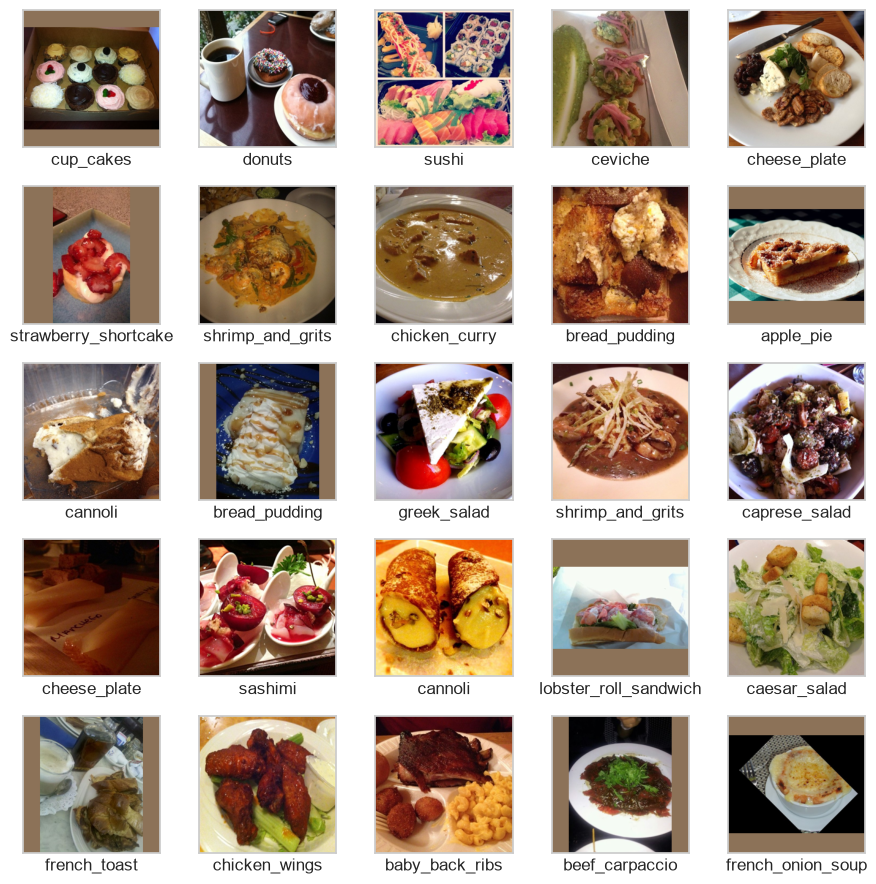

In [70]:
VALID_BATCH_SIZE = 64
NUM_WORKERS = 0

train_dataset       = Subset(Food101Dataset(images_root, transform=train_transform), train_indices)
quick_train_dataset = Subset(Food101Dataset(images_root, transform=train_transform), quick_train_indices)
valid_dataset       = Subset(Food101Dataset(images_root, transform=valid_transform), valid_indices)
test_dataset        = Subset(Food101Dataset(images_root, transform=test_transform), test_indices)

valid_loader       = DataLoader(valid_dataset, batch_size=VALID_BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader        = DataLoader(test_dataset,  batch_size=VALID_BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

def display_sample(dataset, n_samples=25):
    # Dimension [3] to [3, 1, 1], allowing multiplication with tensor image
    mean = train_mean.view(3, 1, 1)
    std = train_std.view(3, 1, 1)

    # Pick random images from the dataset
    sample_indices = torch.randperm(len(dataset))[:n_samples]

    plt.figure(figsize=(9, 9))
    for i, index in enumerate(sample_indices):
        image, label = dataset[index.item()]

        image = (image * std + mean).clamp(0, 1) # Undo normalization to correctly display colors

        plt.subplot(5, 5, i + 1)
        plt.xticks([])
        plt.yticks([])
        plt.grid(False)
        plt.imshow(image.permute(1, 2, 0)) # Reorder [C, H, W] to [H, W, C], aka what Matplotlib expects
        plt.xlabel(full_dataset.classes[int(label)])

    plt.tight_layout()
    plt.show()

display_sample(train_dataset)

## Building the CNN

The holy grail of this project. But lets start **simple** or maybe not.

In [73]:
class Food101CNN(nn.Module):
    def __init__(self, n_classes: int, activation: str):
        super().__init__()

        def make_activation():
            if activation == "relu":
                return nn.ReLU(inplace=True)
            if activation == "mish":
                return nn.Mish(inplace=True)
            raise ValueError(f"Unsupported activation: {activation}. Use 'relu' or 'mish'.")

        def conv_block(in_channels, out_channels, dropout):
            return nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
                nn.BatchNorm2d(out_channels),
                make_activation(),

                nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
                nn.BatchNorm2d(out_channels),
                make_activation(),

                nn.MaxPool2d(kernel_size=2),
                nn.Dropout2d(dropout)
            )

        self.features = nn.Sequential(
            conv_block(3, 32, dropout=0.05),    # 224 -> 112
            conv_block(32, 64, dropout=0.10),   # 112 -> 56
            conv_block(64, 128, dropout=0.15),  # 56 -> 28
            conv_block(128, 256, dropout=0.20)  # 28 -> 14
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)), # Average single channel to single value, 14 -> 1
            nn.Flatten(),
            nn.Linear(256, 256),
            make_activation(),
            nn.Dropout(0.45),
            nn.Linear(256, n_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

torchinfo.summary(
    Food101CNN(n_classes=len(full_dataset.classes), activation="relu").to(device),
    input_size=(1, 3, IMAGE_SIZE, IMAGE_SIZE), device=device
)

Layer (type:depth-idx)                   Output Shape              Param #
Food101CNN                               [1, 101]                  --
├─Sequential: 1-1                        [1, 256, 14, 14]          --
│    └─Sequential: 2-1                   [1, 32, 112, 112]         --
│    │    └─Conv2d: 3-1                  [1, 32, 224, 224]         896
│    │    └─BatchNorm2d: 3-2             [1, 32, 224, 224]         64
│    │    └─ReLU: 3-3                    [1, 32, 224, 224]         --
│    │    └─Conv2d: 3-4                  [1, 32, 224, 224]         9,248
│    │    └─BatchNorm2d: 3-5             [1, 32, 224, 224]         64
│    │    └─ReLU: 3-6                    [1, 32, 224, 224]         --
│    │    └─MaxPool2d: 3-7               [1, 32, 112, 112]         --
│    │    └─Dropout2d: 3-8               [1, 32, 112, 112]         --
│    └─Sequential: 2-2                   [1, 64, 56, 56]           --
│    │    └─Conv2d: 3-9                  [1, 64, 112, 112]         18,496
│    │ 

## Training the model

Let's see how long it takes!

For this first model training I chose **64 batch size** and **25 epochs**. Learning rate is **0.001** and weight decay is **0.0001**.

In [74]:
def show_history(history, n_epochs):
    if not history["train_loss"]:
        return

    epochs = range(1, len(history["train_loss"]) + 1)

    clear_output(wait=True) # Clear old output
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

    ax1.plot(epochs, history["train_loss"], label="train_loss")
    ax1.plot(epochs, history["val_loss"], label="val_loss")
    ax1.set_xlabel("Epoch")
    ax1.set_ylabel("Loss")
    ax1.set_title("Loss")
    ax1.legend()

    ax2.plot(epochs, history["val_acc"], label="val_acc", color="green")
    ax2.set_xlabel("Epoch")
    ax2.set_ylabel("Accuracy")
    ax2.set_title("Validation accuracy")
    ax2.legend()

    plt.tight_layout()
    plt.show()

    for i in range(len(history["train_loss"])):
        epoch_minutes = float(history["epoch_seconds"][i]) / 60
        print(
            f"epoch {i + 1:2d}/{n_epochs}  "
            f"train_loss={history['train_loss'][i]:.3f}  "
            f"val_loss={history['val_loss'][i]:.3f}  "
            f"val_acc={history['val_acc'][i]:.3f}  "
            f"time={epoch_minutes:.2f} min"
        )

def train_model(model_name, train_data, valid_data, n_epochs, activation, optimizer_type, lr, weight_decay, *, patience=8, min_delta=1e-3):
    model = Food101CNN(n_classes=len(full_dataset.classes), activation=activation).to(device)

    criterion = nn.CrossEntropyLoss()
    if optimizer_type == "adam":
        optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    elif optimizer_type == "adamw":
        optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    else:
        raise ValueError(f"Unsupported optimizer: {optimizer_type}. Use 'adam' or 'adamw'.")
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs)

    history = {"train_loss": [], "val_loss": [], "val_acc": [], "epoch_seconds": []}
    start_epoch = 0
    best_val_loss = float("inf")
    epochs_without_improvement = 0

    # Load latest checkpoint
    model_checkpoint_dir = CHECKPOINT_PATH / model_name
    model_checkpoint_dir.mkdir(exist_ok=True)
    checkpoint_paths = list(model_checkpoint_dir.glob("epoch_*.pt"))
    if checkpoint_paths:
        latest_checkpoint = max(checkpoint_paths, key=lambda path: int(path.stem.removeprefix("epoch_")))
        checkpoint = torch.load(latest_checkpoint, map_location=device, weights_only=True)

        model.load_state_dict(checkpoint["model_state"])
        optimizer.load_state_dict(checkpoint["optimizer_state"])
        scheduler.load_state_dict(checkpoint["scheduler_state"])
        history = checkpoint["history"]
        start_epoch = checkpoint["epoch"]
        best_val_loss = checkpoint["best_val_loss"]
        epochs_without_improvement = checkpoint["epochs_without_improvement"]

    # Show previous learning history
    show_history(history, n_epochs)

    for epoch in range(start_epoch, n_epochs):
        # Start timer
        synchronize_device()
        epoch_start = time.perf_counter()

        # Training
        model.train()
        running = 0.0
        for xb, yb in train_data:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()                 # 0) reset gradients
            logits = model(xb)                    # 1) forward pass
            loss = criterion(logits, yb)          # 2) loss
            loss.backward()                       # 3) backward pass (autograd)
            optimizer.step()                      # 4) update the weights
            running += loss.item() * xb.size(0)
        train_loss = running / len(train_data.dataset)
        scheduler.step()

        # Validation
        model.eval()
        vloss, correct = 0.0, 0
        with torch.no_grad():
            for xb, yb in valid_data:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb)
                vloss += criterion(logits, yb).item() * xb.size(0)
                correct += (logits.argmax(1) == yb).sum().item()
        val_loss = vloss / len(valid_data.dataset)
        val_acc  = correct / len(valid_data.dataset)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        if val_loss < best_val_loss - min_delta:
            best_val_loss = val_loss
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        # Stop timer
        synchronize_device()
        history["epoch_seconds"].append(time.perf_counter() - epoch_start)

        # Show learning history
        show_history(history, n_epochs)

        # Save checkpoint
        torch.save({
            "epoch": epoch + 1,
            "model_state": model.state_dict(),
            "optimizer_state": optimizer.state_dict(),
            "scheduler_state": scheduler.state_dict(),
            "history": history,
            "best_val_loss": best_val_loss,
            "epochs_without_improvement": epochs_without_improvement,
        }, model_checkpoint_dir / f"epoch_{epoch + 1:03d}.pt")

        if epochs_without_improvement >= patience:
            print(f"Early stopping at epoch {epoch + 1}: validation loss did not improve.")
            break

    total_seconds = sum(float(seconds) for seconds in history.get("epoch_seconds", []))
    hours, remainder = divmod(int(total_seconds), 3600)
    minutes, seconds = divmod(remainder, 60)
    print(f"Total training time: {hours} h {minutes} min {seconds} s")

    return model

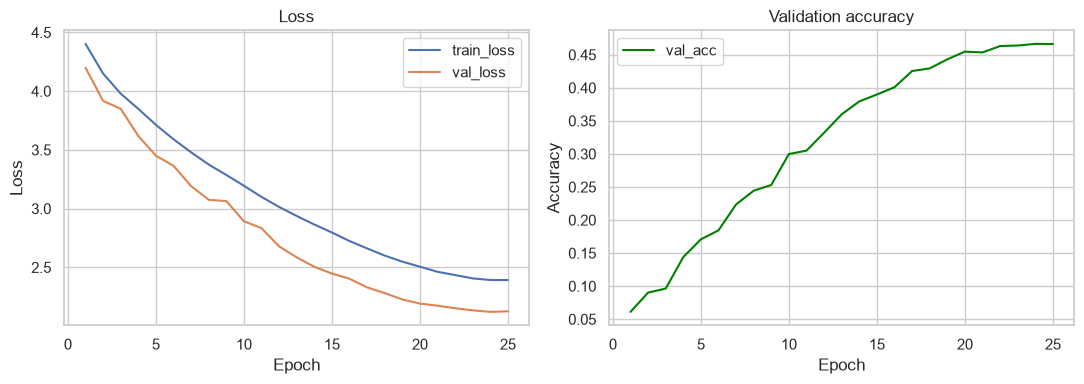

epoch  1/25  train_loss=4.402  val_loss=4.200  val_acc=0.061  time=9.47 min
epoch  2/25  train_loss=4.150  val_loss=3.917  val_acc=0.090  time=9.70 min
epoch  3/25  train_loss=3.978  val_loss=3.850  val_acc=0.096  time=9.70 min
epoch  4/25  train_loss=3.849  val_loss=3.618  val_acc=0.144  time=9.74 min
epoch  5/25  train_loss=3.713  val_loss=3.451  val_acc=0.171  time=10.00 min
epoch  6/25  train_loss=3.590  val_loss=3.364  val_acc=0.184  time=9.75 min
epoch  7/25  train_loss=3.479  val_loss=3.191  val_acc=0.224  time=9.83 min
epoch  8/25  train_loss=3.375  val_loss=3.075  val_acc=0.244  time=9.69 min
epoch  9/25  train_loss=3.286  val_loss=3.064  val_acc=0.253  time=9.77 min
epoch 10/25  train_loss=3.194  val_loss=2.892  val_acc=0.300  time=9.71 min
epoch 11/25  train_loss=3.100  val_loss=2.834  val_acc=0.305  time=9.98 min
epoch 12/25  train_loss=3.014  val_loss=2.678  val_acc=0.332  time=9.69 min
epoch 13/25  train_loss=2.937  val_loss=2.585  val_acc=0.360  time=9.76 min
epoch 14/25

In [75]:
base_model = train_model(
    'base_model',
    DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=NUM_WORKERS),
    valid_loader,
    n_epochs=25,
    activation="relu",
    optimizer_type="adam",
    lr=1e-3,
    weight_decay=1e-4,
    patience=sys.maxsize
)

## Model evaluation

Not bad results for a first attempt! Let's see how it performs on the **test set**.

In [76]:
def evaluate_model(model, test_data):
    model.eval()
    all_preds, all_true = [], []
    with torch.no_grad():
        for xb, yb in test_data:
            xb = xb.to(device)
            logits = model(xb)
            preds = logits.argmax(1).cpu().numpy()   # pick the class with the highest logit
            all_preds.extend(preds)
            all_true.extend(yb.numpy())

    acc = accuracy_score(all_true, all_preds)
    print(f"Test accuracy: {acc:.3f}")

In [77]:
evaluate_model(base_model, test_loader)

Test accuracy: 0.505


## Hyperparameter fine-tuning

But we can do better! Let's tune the hyperparameters on the small subset of the training split.

In [32]:
def optuna_objective(trial, train_set, valid_data, n_epochs):
    activation = trial.suggest_categorical('activation', ['relu', 'mish'])
    optimizer_type = trial.suggest_categorical('optimizer', ['adam', 'adamw'])
    learning_rate = trial.suggest_float('lr', 1e-5, 3e-3, log=True)
    weight_decay = trial.suggest_float('weight_decay', 1e-6, 1e-3, log=True)
    batch_size = trial.suggest_categorical('batch_size', [32, 64])

    train_data = DataLoader(train_set, batch_size=batch_size, shuffle=True, num_workers=NUM_WORKERS)
    model = Food101CNN(n_classes=len(full_dataset.classes), activation=activation).to(device)

    criterion = nn.CrossEntropyLoss()
    if optimizer_type == "adam":
        optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    elif optimizer_type == "adamw":
        optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    else:
        raise ValueError(f"Unsupported optimizer: {optimizer_type}. Use 'adam' or 'adamw'.")
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs)

    best_val_acc = 0.0
    for epoch in range(n_epochs):
        # Training
        model.train()
        for xb, yb in train_data:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
        scheduler.step()

        # Validation
        model.eval()
        correct = 0
        with torch.no_grad():
            for xb, yb in valid_data:
                xb, yb = xb.to(device), yb.to(device)
                correct += (model(xb).argmax(1) == yb).sum().item()
        val_acc = correct / len(valid_data.dataset)
        best_val_acc = max(best_val_acc, val_acc)

        # Trial report
        trial.report(val_acc, epoch)
        if trial.should_prune():
            raise optuna.TrialPruned()

    return best_val_acc

In [39]:
OPTUNA_CHECKPOINT = f"sqlite:///{(CHECKPOINT_PATH / 'optuna.db').resolve()}"

tuning_study = optuna.create_study(
    study_name='food101',
    storage=OPTUNA_CHECKPOINT,
    load_if_exists=True,
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=10, n_warmup_steps=3),
)

[I 2026-10-27 14:16:46,605] A new study created in RDB with name: food101


In [45]:
MAX_TRIALS = 50
MAX_EPOCHS_PER_TRIAL = 8

# Number of finished trials
finished_trials = sum(
    trial.state in {TrialState.COMPLETE, TrialState.PRUNED}
    for trial in tuning_study.trials
)

# Retrieve last failed trial and retry it again
failed_trial = next(
    (
        trial
        for trial in reversed(tuning_study.trials)
        if trial.state == TrialState.FAIL
    ),
    None
)
if failed_trial is not None:
    tuning_study.enqueue_trial(failed_trial.params)

# Run remaining studies
tuning_study.optimize(
    partial(optuna_objective,
        train_set=quick_train_dataset,
        valid_data=valid_loader,
        n_epochs=MAX_EPOCHS_PER_TRIAL
    ),
    n_trials=max(0, MAX_TRIALS - finished_trials)
)

print(f"Best validation accuracy: {tuning_study.best_value:.3f}")
print(f"Best hyperparameters: {tuning_study.best_params}")

[I 2026-10-28 09:32:41,232] Trial 37 finished with value: 0.08488448844884489 and parameters: {'activation': 'mish', 'optimizer': 'adamw', 'lr': 0.0002699154023591691, 'weight_decay': 0.0006494961933618463, 'batch_size': 32}. Best is trial 26 with value: 0.09465346534653465.
[I 2026-10-28 09:37:53,487] Trial 38 pruned. 
[I 2026-10-28 09:43:16,364] Trial 39 pruned. 
[I 2026-10-28 09:48:28,114] Trial 40 pruned. 
[I 2026-10-28 09:58:49,727] Trial 41 finished with value: 0.09927392739273927 and parameters: {'activation': 'mish', 'optimizer': 'adamw', 'lr': 0.0007089183083525234, 'weight_decay': 2.5421993862002234e-05, 'batch_size': 32}. Best is trial 41 with value: 0.09927392739273927.
[I 2026-10-28 10:04:00,109] Trial 42 pruned. 
[I 2026-10-28 10:09:25,914] Trial 43 pruned. 
[I 2026-10-28 10:19:54,857] Trial 44 finished with value: 0.09201320132013201 and parameters: {'activation': 'mish', 'optimizer': 'adamw', 'lr': 0.00044691598839872044, 'weight_decay': 5.751708320424711e-06, 'batch_si

Best validation accuracy: 0.099
Best hyperparameters: {'activation': 'mish', 'optimizer': 'adamw', 'lr': 0.0007089183083525234, 'weight_decay': 2.5421993862002234e-05, 'batch_size': 32}


## Training the model AGAIN

Let's retrain model again **with our fine-tuned hyperparameters**.

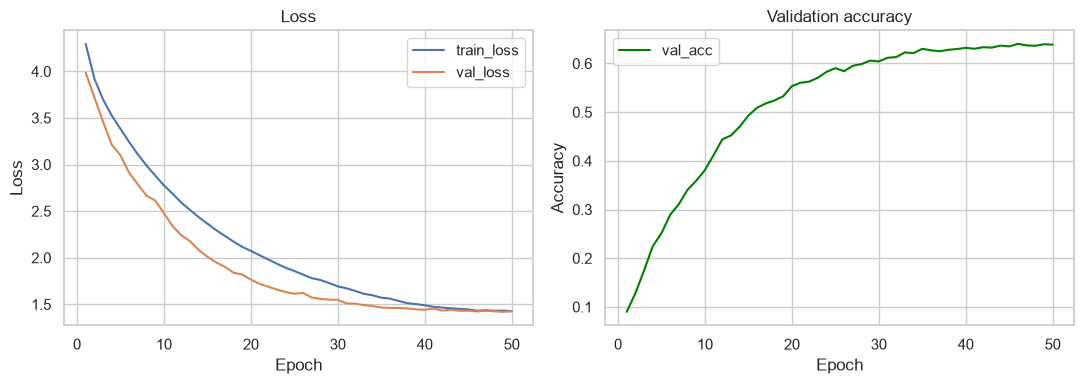

epoch  1/50  train_loss=4.295  val_loss=3.985  val_acc=0.090  time=10.46 min
epoch  2/50  train_loss=3.921  val_loss=3.721  val_acc=0.128  time=10.26 min
epoch  3/50  train_loss=3.698  val_loss=3.458  val_acc=0.175  time=10.14 min
epoch  4/50  train_loss=3.524  val_loss=3.212  val_acc=0.225  time=10.09 min
epoch  5/50  train_loss=3.383  val_loss=3.099  val_acc=0.251  time=10.32 min
epoch  6/50  train_loss=3.241  val_loss=2.910  val_acc=0.289  time=10.28 min
epoch  7/50  train_loss=3.108  val_loss=2.786  val_acc=0.311  time=10.33 min
epoch  8/50  train_loss=2.989  val_loss=2.665  val_acc=0.341  time=10.48 min
epoch  9/50  train_loss=2.881  val_loss=2.613  val_acc=0.359  time=10.11 min
epoch 10/50  train_loss=2.776  val_loss=2.477  val_acc=0.381  time=10.10 min
epoch 11/50  train_loss=2.686  val_loss=2.338  val_acc=0.412  time=10.18 min
epoch 12/50  train_loss=2.591  val_loss=2.240  val_acc=0.444  time=10.09 min
epoch 13/50  train_loss=2.513  val_loss=2.177  val_acc=0.452  time=10.12 min

In [78]:
tuned_model = train_model(
    'tuned_model',
    DataLoader(train_dataset, batch_size=tuning_study.best_params['batch_size'], shuffle=True, num_workers=NUM_WORKERS),
    valid_loader,
    n_epochs=50,
    activation=tuning_study.best_params['activation'],
    optimizer_type=tuning_study.best_params['optimizer'],
    lr=tuning_study.best_params['lr'],
    weight_decay=tuning_study.best_params['weight_decay']
)

In [79]:
evaluate_model(tuned_model, test_loader)

Test accuracy: 0.678


## Visualizing model predictions

We can again show sample of images, but **with predicted labels** instead.

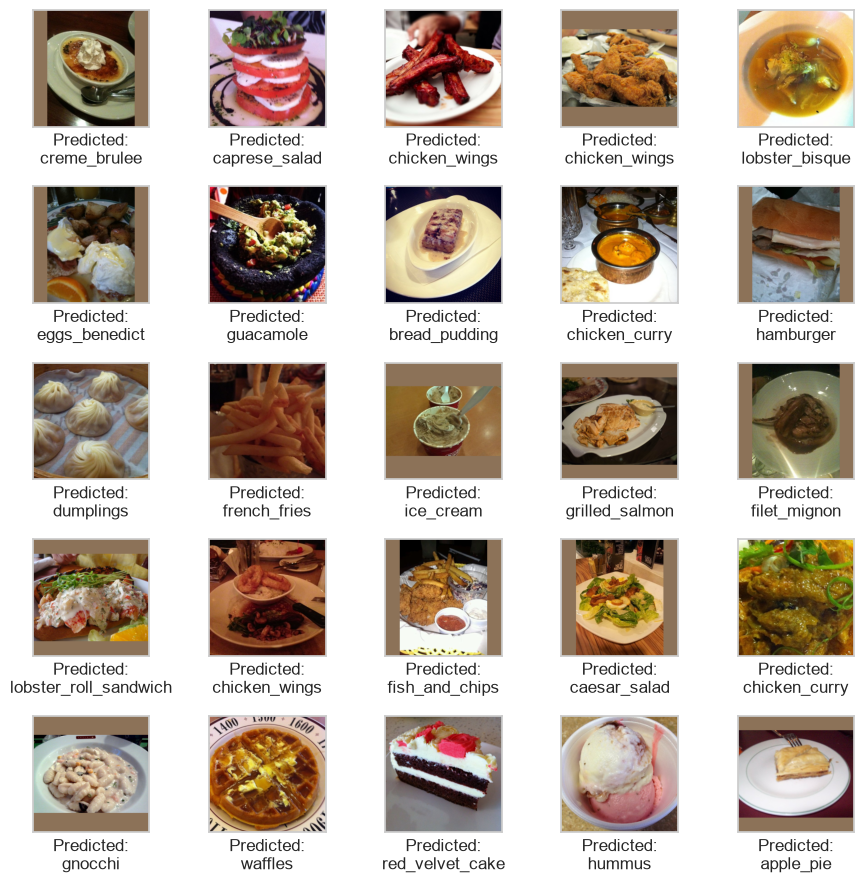

In [80]:
def display_predictions(model, dataset, n_samples=25):
    # Pick random images from the dataset.
    indices = torch.randperm(len(dataset))[:n_samples]

    # Convert images into single batch for single pass prediction
    images = torch.stack([
        dataset[index.item()][0]
        for index in indices
    ])

    # Predict without training or storing gradients
    model.eval()
    with torch.no_grad():
        predictions = model(images.to(device)).argmax(dim=1).cpu()

    # Dimension [3] to [3, 1, 1], allowing multiplication with tensor image
    mean = train_mean.view(3, 1, 1)
    std = train_std.view(3, 1, 1)

    plt.figure(figsize=(9, 9))
    for i in range(n_samples):
        image = (images[i] * std + mean).clamp(0, 1) # Undo normalization to correctly display colors

        plt.subplot(5, 5, i + 1)
        plt.xticks([])
        plt.yticks([])
        plt.grid(False)

        plt.imshow(image.permute(1, 2, 0)) # Reorder [C, H, W] to [H, W, C], aka what Matplotlib expects

        plt.xlabel(f"Predicted:\n{full_dataset.classes[predictions[i]]}")

    plt.tight_layout()
    plt.show()

display_predictions(tuned_model, test_dataset)